# Optimizing document review agents for cost and quality

**The promise:** find which steps need an LLM and which need only a decision model, and prove it with numbers.

A law firm's e-discovery agent reads each page of a company's files and decides what to hand to the other side in a lawsuit. We make it cheaper and faster, one change at a time.

In [1]:
%matplotlib inline
import os

import pandas as pd
from dotenv import load_dotenv
from IPython.display import display
from openai import AsyncOpenAI

load_dotenv(override=False)
RUN_LIVE_API_CALLS = os.environ.get("RUN_LIVE_API_CALLS", "false").lower() == "true"
LANGSMITH_TRACING = os.environ.get("LANGSMITH_TRACING", "false").lower() == "true"
if RUN_LIVE_API_CALLS and not os.environ.get("OPENAI_API_KEY"):
    raise RuntimeError("Set OPENAI_API_KEY before enabling live API calls.")
if LANGSMITH_TRACING and not os.environ.get("LANGSMITH_API_KEY"):
    raise RuntimeError("Set LANGSMITH_API_KEY before enabling LangSmith tracing.")
os.environ["LANGSMITH_TRACING"] = str(LANGSMITH_TRACING).lower()
os.environ["LANGCHAIN_TRACING_V2"] = str(LANGSMITH_TRACING).lower()
os.environ.setdefault("LANGSMITH_PROJECT", "doc-review-opt")
from doc_review_opt.config import get_settings
from doc_review_opt.experiment.live import BudgetTracker
from doc_review_opt.reporting.diagrams import draw_diagram
LIVE = get_settings().live
client = AsyncOpenAI(timeout=LIVE.timeout_s, max_retries=LIVE.max_retries) if RUN_LIVE_API_CALLS else None
budget = BudgetTracker()
print(f"Live: {RUN_LIVE_API_CALLS} | LangSmith: {LANGSMITH_TRACING} | budget stop: ${budget.limit_usd:.2f}")

Live: False | LangSmith: False | budget stop: $1.00


## Agenda: 20 minutes

| Steps | What | Min |
|---|---|---|
| 1-2 | The system and what we optimize | 3 |
| 3-4 | The test set and the starting point | 2 |
| 5-6 | One page, then harder pages | 2 |
| 7-11 | Five rounds, one change each | 8 |
| 12 | Results | 3 |
| 13-14 | Live check and takeaways | 2 |

## Step 1: The system in one picture

A page goes in. One of four outcomes comes out: **produce**, **withhold**, **redact** (then produce) or **attorney review**.

Three parts decide:
1. **The engine** answers three questions: is the page relevant, is it privileged (lawyer advice), does it contain personal data?
2. **The router** is plain code. It turns the three answers into one outcome.
3. **An attorney** is asked only when the system is unsure or privilege is at stake.

| The page is… | Outcome | Why it matters |
|---|---|---|
| Lawyer-client advice (privileged) | **attorney review**, then withhold | Producing it can waive privilege |
| Not relevant to the case | **withhold** | Nothing to hand over |
| Relevant, with personal data | **redact**, then produce | Personal data must not leak |
| Relevant and clean | **produce** | |
| Unclear | **attorney review** | Safe, but $1.50 of attorney time |

The system runs as a LangGraph graph: boxes and arrows. `Send` starts one copy per page, in parallel. `classify` asks the engine. `attorney_review` calls `interrupt()`, which pauses the run until a person answers. Every round keeps this graph; only what runs inside the boxes changes.

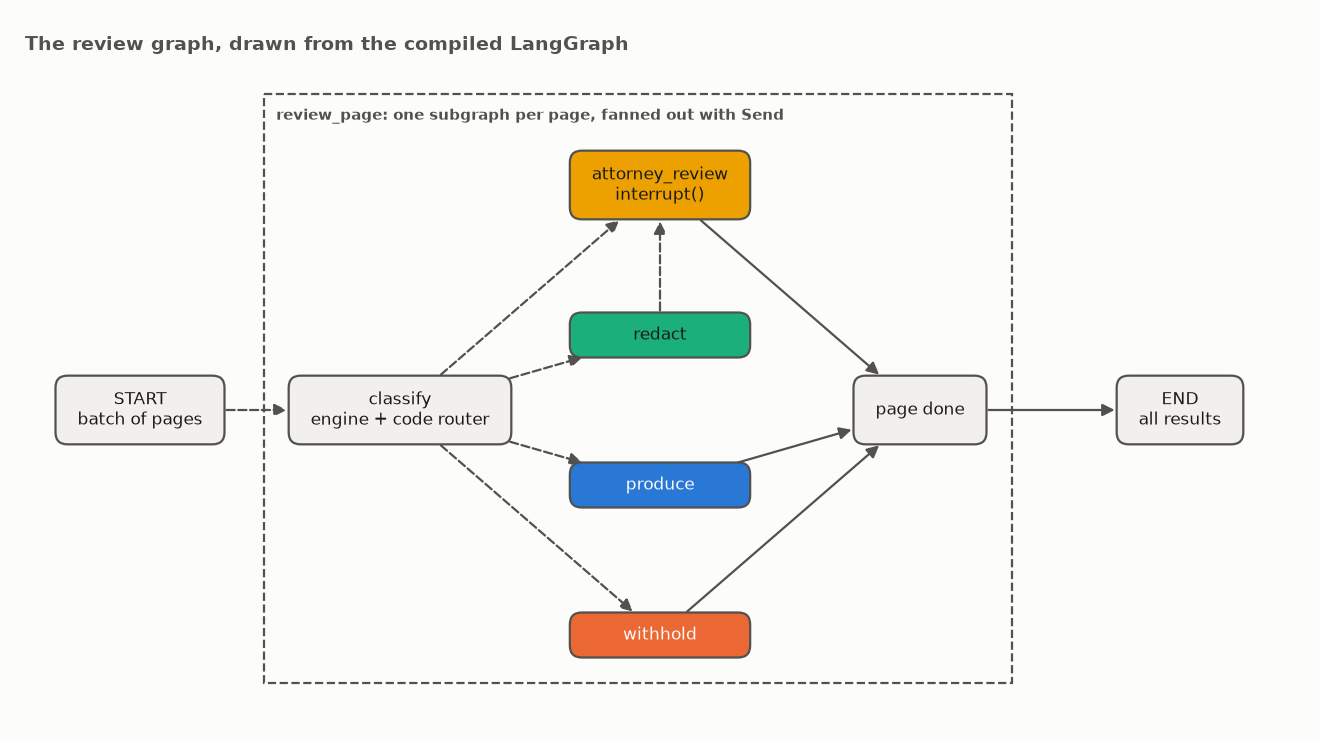

In [2]:
from doc_review_opt.agent.graph import build_review_graph, review_checkpointer
from doc_review_opt.agent.variants import BASELINE, VARIANTS, default_policy
from doc_review_opt.experiment.simulation import build_simulated_engines
from doc_review_opt.fixtures import EVAL_SET
from doc_review_opt.reporting.diagrams import draw_graph

policy = default_policy(VARIANTS[BASELINE])
engine, redactor = build_simulated_engines(VARIANTS[BASELINE], EVAL_SET, policy)
review_graph = build_review_graph(engine, redactor, review_checkpointer(), policy=policy)
draw_graph(review_graph.get_graph(xray=True))

Four pages, one per outcome. The privileged page stops at the attorney pause. The pause carries the page id and the reason, never page text. Then the attorney answers and the run finishes.

In [3]:
from uuid import uuid4
from langgraph.types import Command
from doc_review_opt.reporting.walkthrough import page_table
OUTCOMES = ("produce", "withhold", "redact", "attorney_review")
demo_pages = [next(p for p in EVAL_SET if p.labels.expected_route == o) for o in OUTCOMES]
config = {"configurable": {"thread_id": f"intro-{uuid4()}"}}
paused = await review_graph.ainvoke({"pages": demo_pages, "results": []}, config)
waiting = [pending.value["doc_id"] for pending in paused["__interrupt__"]]
print(f"{len(paused['results'])} pages finished, {len(waiting)} waiting for an attorney: {', '.join(waiting)}")
resume = {pending.id: "withhold" for pending in paused["__interrupt__"]}
final = await review_graph.ainvoke(Command(resume=resume), config)
display(page_table(demo_pages, final["results"]).style.hide(axis="index"))

3 pages finished, 1 waiting for an attorney: ARC-000284


doc_id,page,from,expected,route,decision
ARC-000141,Q3 2024 REVENUE SUMMARY (INTERNAL),Finance Reporting,produce,produce,produce
ARC-000212,FACILITIES NOTICE,Ines Calloway,withhold,withhold,withhold
ARC-000352,SALES OPS EMAIL,Noor Haddad,redact,redact,produce
ARC-000284,EMAIL,Priya Raghunathan (attorney),attorney_review,attorney_review,withhold


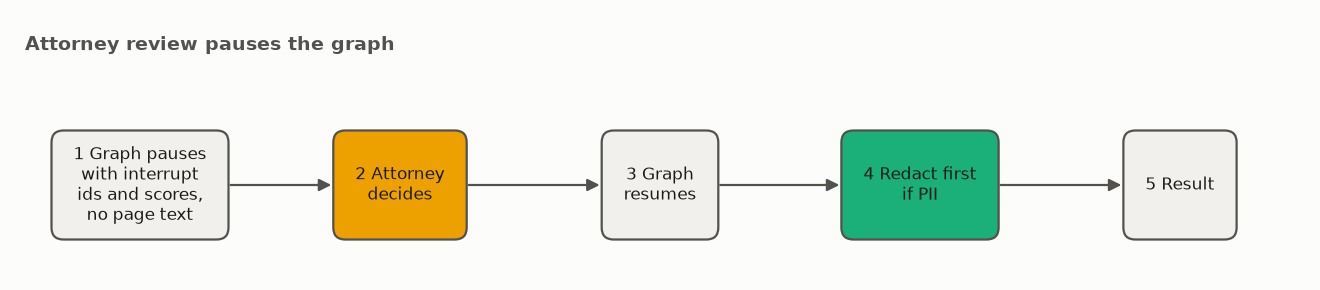

In [4]:
draw_diagram("human_in_the_loop")

## Step 2: What we optimize

**Make each page cheaper and faster without ever breaking the two hard rules:** never produce a privileged page, never leave personal data in a produced page.

| Lever | What it changes | Cost it attacks |
|---|---|---|
| Controls | Tight prompt, fewer tools, strict JSON | Tokens |
| Model routing | Cheap model for routine pages | Model price |
| Decision model | One call to the Decisions API (typed answers, not free text) plus a code router | Latency, price |
| Prompt caching | Reuse the unchanged prompt start | Input tokens |
| Workflow split | Side jobs move to Batch | Waiting time |

The same test runs after every change:

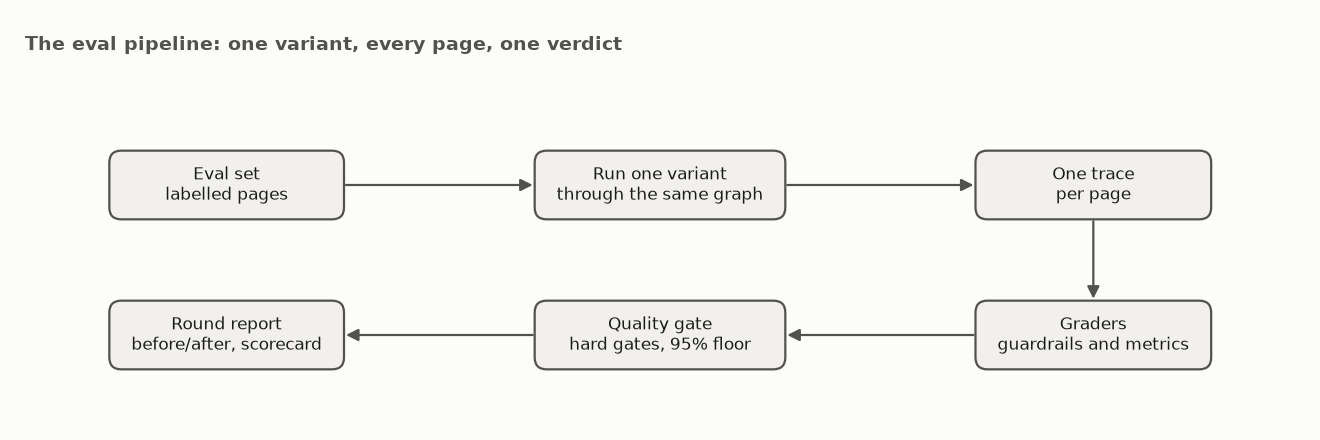

In [5]:
draw_diagram("eval_pipeline")

A *trace* is the record of one page's run: what the engine did, tokens, seconds, cost, outcome. A *gate* is a pass/fail check. Hard gates and a pass rate of at least 95% of pages (the guardrail pass floor) accept or reject a round. Other metrics only warn, marked **(watch)** when below their floor. No LLM judge.

## Step 3: The test set

60 synthetic, labelled pages for one lawsuit; 23 are traps or borderline. The first 30 were written first; 30 more add harder kinds: a lawyer only on cc, relayed advice, personal data in an irrelevant page, damaged scans, near-duplicates. Zero privileged pages produced and zero personal data left in produced text are the hard gates.

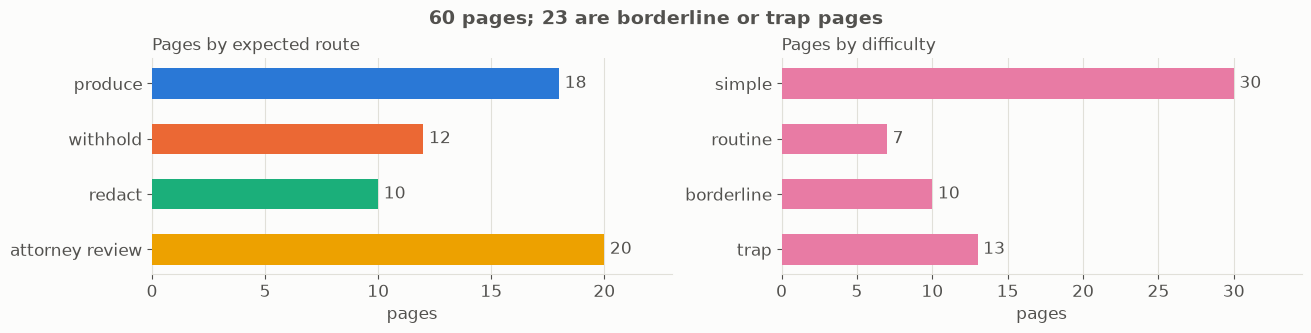

In [6]:
from doc_review_opt.reporting.reporting import plot_eval_set

eval_table = pd.DataFrame(
    {
        "doc_id": page.doc_id,
        "expected_route": page.labels.expected_route,
        "difficulty": page.labels.difficulty,
    }
    for page in EVAL_SET
)
display(plot_eval_set(eval_table))

## Step 4: The starting point

One `gpt-6.1-terra` agent does everything: every tool on every page, verbose payloads, free-text answer. We run it on all 60 pages (simulated, seconds). **p50 latency** is the typical page's time: half the pages are faster.

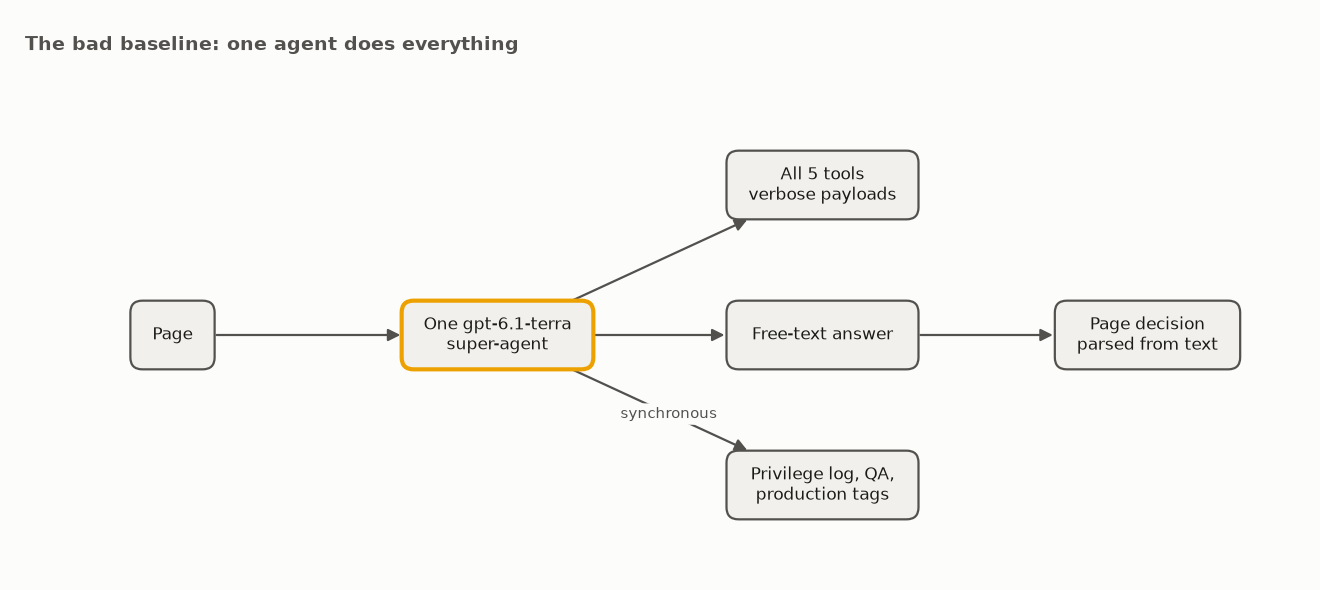

In [7]:
draw_diagram("bad_baseline")

In [8]:
from doc_review_opt.agent.variants import BASELINE, CACHING, CALIBRATED_POLICY, CONTROLS, DECISION_MODEL, ROUTING, SPLIT, VARIANT_ORDER
from doc_review_opt.experiment.simulation import simulate_all
from doc_review_opt.experiment.traces import traces_frame
from doc_review_opt.reporting.reporting import plot_progress, plot_quality_gate, plot_round_chart, summarize
from doc_review_opt.reporting.walkthrough import before_after, confusion_table, follow_page, gate, gate_table, holdout_table, metrics_table, outcome_table, symptoms

traces = await simulate_all()
summary = summarize(traces_frame(traces))
SAMPLE_PAGE = next(p for p in EVAL_SET if p.labels.privileged)
CLEAN_PAGE = next(p for p in EVAL_SET if p.doc_id == "ARC-000289")

In [9]:
print(symptoms(summary, BASELINE))
print(gate(traces, BASELINE))
display(metrics_table(traces, [BASELINE]).style.hide(axis="index"))

Bad baseline
  tool calls: 5.0 per page (4.2 unneeded)
  sync tokens: 8,474 per page
  p50 latency: 3.59s
  model cost: $0.00895 per page
  escalation rate: 47%
  leaks: privileged 0, PII 2
Bad baseline: REJECTED (guardrail pass 0%, floor 95%; failures: too_many_unnecessary_tools=60, escalation_mismatch=8, unnecessary_attorney_review=8, unparseable_agent_output=1, pii_in_produced_text=2)


kind,metric,Bad baseline
hard gate,privileged pages produced (must be 0),0
hard gate,PII leaked pages (must be 0),2
hard gate,guardrail pass rate (floor 95%),0%
hard gate,round accepted,no
reported,route accuracy,83% (watch)
reported,relevance recall,100%
reported,over-withholding rate,0%
reported,privileged recall,100%
reported,PII recall,93% (watch)
reported,under-escalation rate,0%


**Errors found:** 4.2 of 5 tool calls per page are unneeded, about 8.5k tokens per page, personal data left in produced text on 2 pages, route accuracy 83%, 20% needless attorney reviews. Each round fixes one thing.

## Step 5: Follow one page through every round

Same page, six runs. Each row is one trace: engine, tools called, tokens, seconds, model cost, and the outcome with the router's reason.

In [10]:
for page in (SAMPLE_PAGE, CLEAN_PAGE):
    display(page_table([page]).style.hide(axis="index"))
    display(follow_page(traces, page.doc_id).style.hide(axis="index"))

doc_id,page,from,expected
ARC-000284,EMAIL,Priya Raghunathan (attorney),attorney_review


round,engine and model,tools called,tokens,seconds,model cost,outcome,reason
Bad baseline,agent: gpt-6.1-terra,5,"8,641",3.59,$0.00917,"attorney review, then withhold",agent disposition
Round 1: controls,agent: gpt-6.1-terra,2,"1,254",1.73,$0.00133,"attorney review, then withhold",agent disposition
Round 2: routing,"agent: gpt-6-luna, gpt-6.1-terra",2,"1,429",1.89,$0.00128,"attorney review, then withhold",agent disposition
Round 3: decision model,decisions: gpt-6-luna,0,"2,075",0.67,$0.00024,"attorney review, then withhold",privilege above threshold
Round 4: caching,decisions: gpt-6-luna,0,"2,075",0.65,$0.00013,"attorney review, then withhold",privilege above threshold
Round 5: split workflow,decisions: gpt-6-luna,0,"1,712",0.11,$0.00014,"attorney review, then withhold",privilege above threshold


doc_id,page,from,expected
ARC-000289,Q3 CLOSE CHECKLIST (EXCERPT),Yusuf Demir,produce


round,engine and model,tools called,tokens,seconds,model cost,outcome,reason
Bad baseline,agent: gpt-6.1-terra,5,"8,633",3.59,$0.00915,produce,agent disposition
Round 1: controls,agent: gpt-6.1-terra,0,"1,211",1.45,$0.00128,produce,agent disposition
Round 2: routing,agent: gpt-6-luna,0,"1,382",1.24,$0.00016,produce,agent disposition
Round 3: decision model,decisions: gpt-6-luna,0,"2,067",0.67,$0.00024,produce,clean responsive
Round 4: caching,decisions: gpt-6-luna,0,"2,067",0.65,$0.00013,produce,clean responsive
Round 5: split workflow,decisions: gpt-6-luna,0,"1,708",0.11,$0.00011,produce,clean responsive


**The privileged page** goes to an attorney in every round; no lever changes the safe outcome. Only the bill falls: 8,641 tokens and 3.59s become 1,712 tokens and 0.11s.

**The clean page** is produced in every round. Its cost falls from $0.00915 to $0.00011, and the 5 tools the baseline called become 0.

## Step 6: Harder pages

Same rules, trickier pages. The table shows what the labels expect and what Round 5 did.

- **ARC-000615:** a lawyer is only on cc and nobody asks for advice.
- **ARC-000622:** a "privileged" stamp, but no lawyer and no advice.
- **ARC-000643:** full of personal data but irrelevant to the case.
- **ARC-000649:** a resent copy of pages already produced.
- **ARC-000684:** "our lawyers said", with no lawyer named.
- **ARC-000665:** a long workpaper with a phone number and email at the end.

In [11]:
TRICKY = ("ARC-000615", "ARC-000622", "ARC-000643", "ARC-000649", "ARC-000684", "ARC-000665")
tricky_pages = [next(p for p in EVAL_SET if p.doc_id == doc_id) for doc_id in TRICKY]
display(outcome_table(traces, tricky_pages, SPLIT).style.hide(axis="index"))

doc_id,page,from,expected,route,reason
ARC-000615,EMAIL,Marcus Oyelaran,produce,produce,clean responsive
ARC-000622,PRIVILEGED & CONFIDENTIAL STAMP (CLOSE SCHEDULE),Yusuf Demir,produce,produce,clean responsive
ARC-000643,WAGE GARNISHMENT ORDER (HR FILE),Owen Fitch,withhold,withhold,not responsive
ARC-000649,AUDIT COMMITTEE MINUTES (EXCERPT) -- RESENT COPY,Lena Ortiz,withhold,withhold,agent disposition
ARC-000684,EMAIL,Nadia Brooks,attorney_review,attorney_review,privilege above threshold
ARC-000665,Q3 CUTOFF WORKPAPER WP-Q3-CUTOFF-17,Yusuf Demir,redact,redact,pii above threshold


## Step 7: Round 1, controls

**What we changed:** a tight prompt, only the tools a page needs, slim tool results, and a strict JSON answer.

**What happened:** tool calls fall from 5.0 to 0.8 per page, tokens from 8,474 to 1,335, model cost from $0.00895 to $0.00136. Personal-data leaks go from 2 pages to 0.

**Why:** the baseline paid for work it never needed.

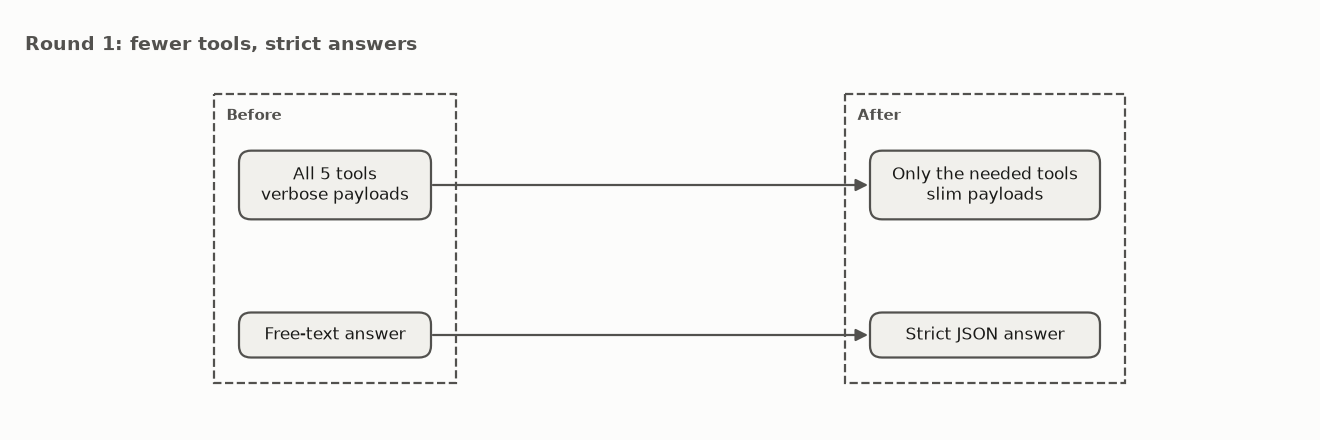

In [12]:
draw_diagram("round1")

metric,before,after
quality,0.80,0.98
privileged leaks,0,0
PII leaks,2,0
escalation rate,47%,33%
tool calls per page,5.0,0.8
sync tokens,"8,474","1,335"
p50 latency (s),3.59,1.59
model $/page,$0.00895,$0.00136
cost with attorney time $/page,$0.709,$0.501


Round 1: controls: ACCEPTED (guardrail pass 100%, floor 95%; failures: none)


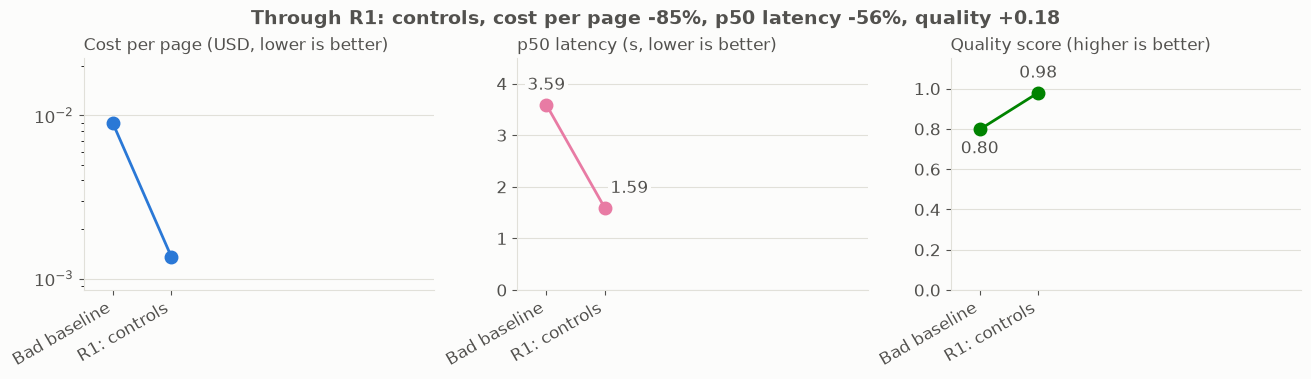

In [13]:
display(before_after(summary, BASELINE, CONTROLS).style.hide(axis="index"))
print(gate(traces, CONTROLS))
display(plot_progress(summary, upto_variant=CONTROLS))

## Step 8: Round 2, model routing

**What we changed:** a cheap `gpt-6-luna` model reads each page first; only risky pages go to the stronger `gpt-6.1-terra`.

**What happened:** model cost falls to $0.00049 per page, the lowest so far. The gate records 1 missed attorney review (guardrail pass 98%), but 1 miss in 60 pages stays above the 95% floor, so Round 2 is accepted.

**Why:** a cheap first pass saves money and can slip. Cheaper is not free.

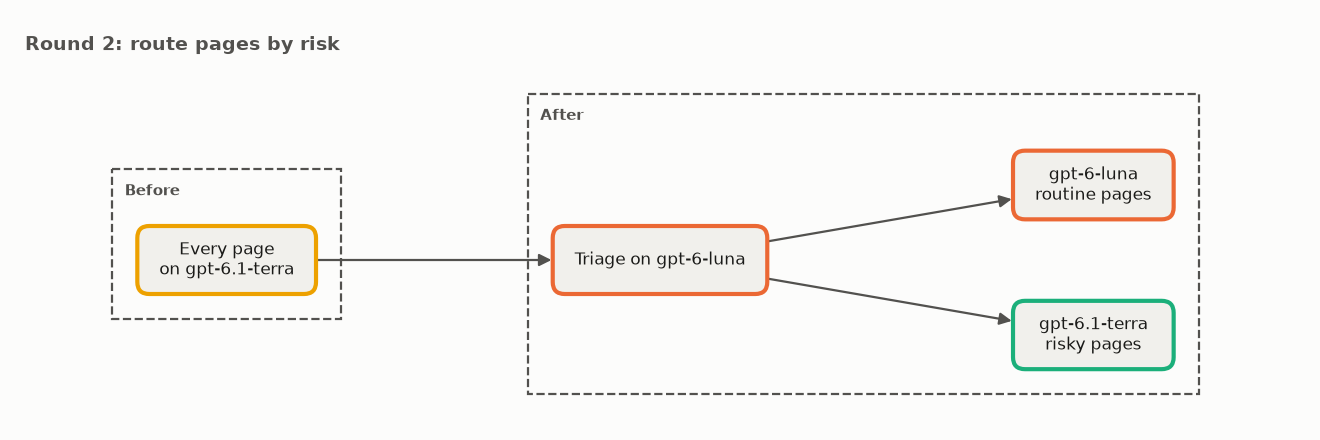

In [14]:
draw_diagram("round2")

metric,before,after
quality,0.98,0.97
privileged leaks,0,0
PII leaks,0,0
escalation rate,33%,32%
tool calls per page,0.8,0.8
sync tokens,"1,335","1,545"
p50 latency (s),1.59,1.38
model $/page,$0.00136,$0.00049
cost with attorney time $/page,$0.501,$0.475


Round 2: routing: ACCEPTED (guardrail pass 98%, floor 95%; failures: escalation_mismatch=1)


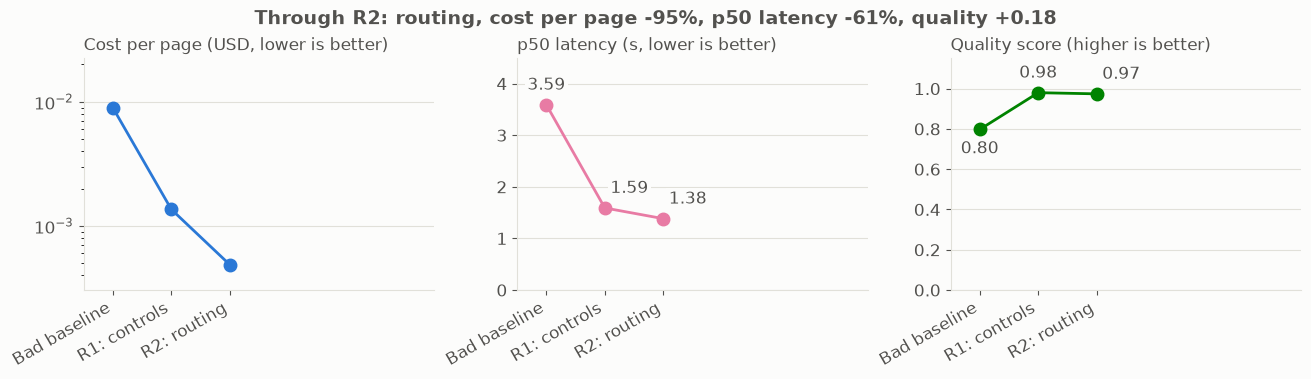

In [15]:
display(before_after(summary, CONTROLS, ROUTING).style.hide(axis="index"))
print(gate(traces, ROUTING))
display(plot_progress(summary, upto_variant=ROUTING))

## Step 9: Round 3, a decision model

**What we changed:** one call to the OpenAI Decisions API asks the three questions and returns typed answers, a score and two yes/no probabilities, not free text. The router (plain code) picks the outcome. A cascade (a cheap model first, a stronger one only when unsure) lets `gpt-6.1-terra` re-check the unsure pages.

**What happened:** p50 latency falls from 1.38s to 0.68s and the missed attorney review is fixed, but model cost rises from $0.00049 to $0.00072 per page.

**Why:** typed answers are fast and can be calibrated (their thresholds tuned on part of the pages); the second opinion costs a little.

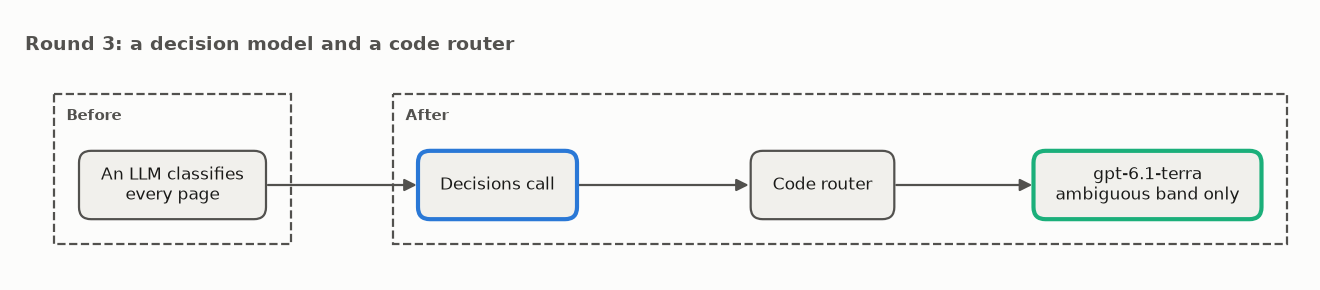

In [16]:
draw_diagram("round3")

metric,before,after
quality,0.97,0.98
privileged leaks,0,0
PII leaks,0,0
escalation rate,32%,33%
tool calls per page,0.8,0.1
sync tokens,"1,545","2,523"
p50 latency (s),1.38,0.68
model $/page,$0.00049,$0.00072
cost with attorney time $/page,$0.475,$0.501


Round 3: decision model: ACCEPTED (guardrail pass 100%, floor 95%; failures: none)


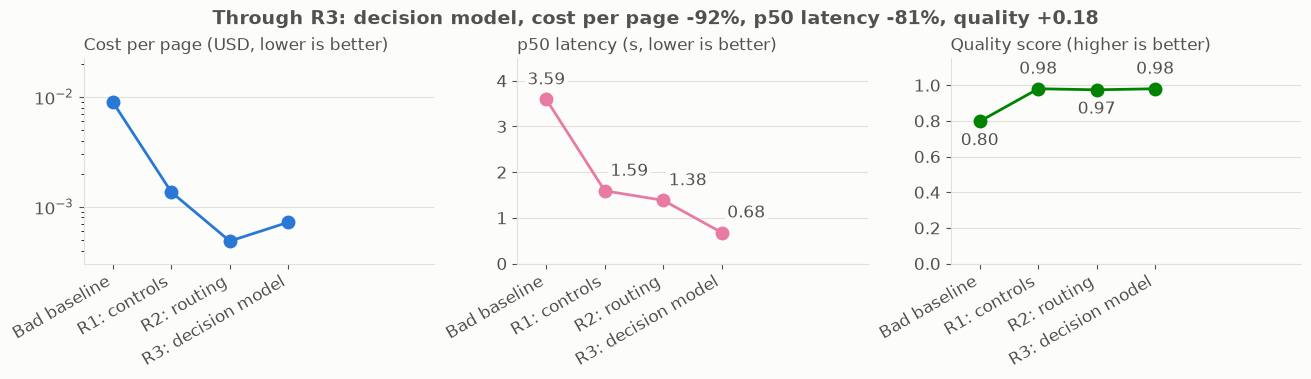

In [17]:
display(before_after(summary, ROUTING, DECISION_MODEL).style.hide(axis="index"))
print(gate(traces, DECISION_MODEL))
display(plot_progress(summary, upto_variant=DECISION_MODEL))

The router is plain code: readable, testable, auditable. A refusal or an error never produces a page; it fails safe to an attorney.

In [18]:
import inspect

from doc_review_opt.agent.routing import decide

print(inspect.getsource(decide))

def decide(
    result: ClassifierResult, policy: RoutingPolicy = DEFAULT_POLICY
) -> RouteDecision:
    if result.error is not None:
        return RouteDecision("attorney_review", "classifier_error")
    if any(isinstance(a, RefusalAnswer) for a in result.answers.values()):
        return RouteDecision("attorney_review", "missing_or_refused_answer")
    if result.agent_disposition is not None:
        return _route_agent(result.agent_disposition, result, policy)
    typed = _typed_answers(result)
    if typed is None:
        return RouteDecision("attorney_review", "missing_or_refused_answer")
    responsive, privileged, pii = typed
    if privileged.probability > policy.privilege_escalation:
        return RouteDecision("attorney_review", "privilege_above_threshold")
    if responsive.score < policy.not_responsive:
        return RouteDecision("withhold", "not_responsive")
    if responsive.score < policy.responsive:
        return RouteDecision("attorney_review", "ambiguous_respons

### Step 9b: LLM or Decisions?

Same three questions, four engines, 60 pages (simulated, calibrated thresholds). **Read it:** Decisions alone is the fastest and cheapest, but it sends more pages to an attorney (50% vs 33% for `gpt-6.1-terra` as an LLM). That is why Round 3 adds the cascade.

Engine,Accuracy,$ / page,p50 (s),To attorney
Decisions (gpt-6-luna),83%,$0.00019,0.13,50%
LLM probabilities (gpt-6-luna),80%,$0.00022,0.81,48%
LLM probabilities (gpt-6.1-terra),97%,$0.00207,1.18,33%
Agent (gpt-6.1-terra),100%,$0.00136,1.59,33%


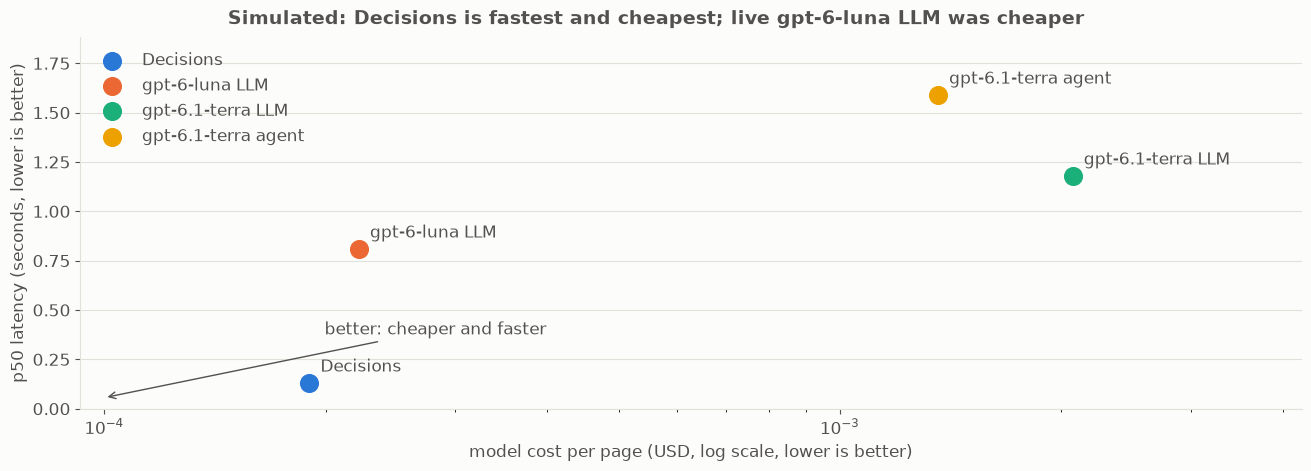

In [19]:
from doc_review_opt.experiment.tradeoffs import engine_comparison_table, plot_engine_tradeoff, simulate_engine_comparison

def show_engines(table):
    view = table[["label", "accuracy_vs_labels", "cost_per_page_usd", "p50_latency_s", "escalation_rate"]]
    view.columns = ["Engine", "Accuracy", "$ / page", "p50 (s)", "To attorney"]
    formats = {"Accuracy": "{:.0%}", "$ / page": "${:.5f}", "p50 (s)": "{:.2f}", "To attorney": "{:.0%}"}
    display(view.style.format(formats).hide(axis="index"))

engine_runs = await simulate_engine_comparison(policy=CALIBRATED_POLICY)
engines = engine_comparison_table(engine_runs)
show_engines(engines)
display(plot_engine_tradeoff(engines))

**Probabilities are a dial.** Move the privilege threshold: Decisions never leaks a privileged page; the LLMs' self-reported probabilities start leaking. Decisions cannot write text, extract spans or call tools, so each step gets the engine it needs.

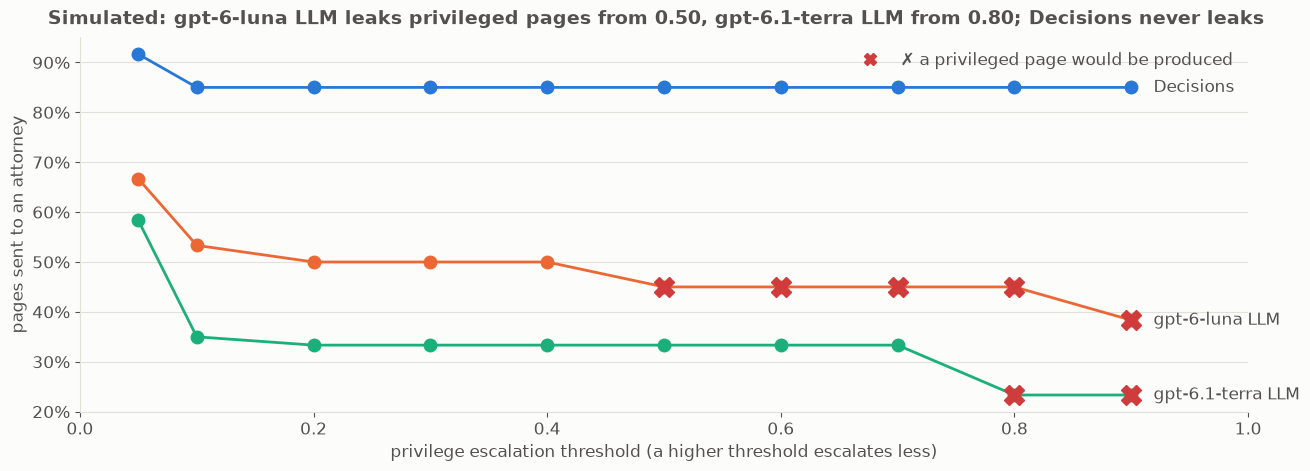

In [20]:
from doc_review_opt.experiment.tradeoffs import plot_threshold_sweep, threshold_sweep

display(plot_threshold_sweep(threshold_sweep(await simulate_engine_comparison(), EVAL_SET)))

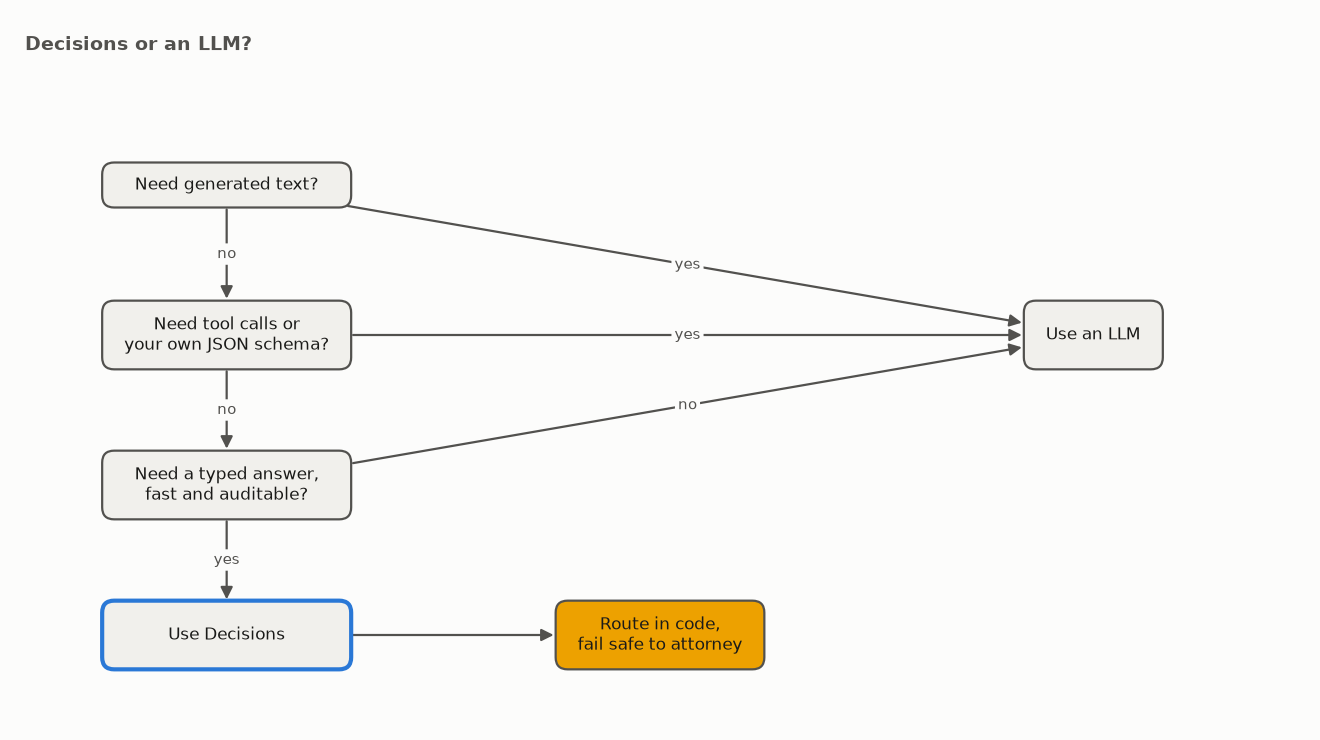

In [21]:
draw_diagram("decisions_or_llm")

## Step 10: Round 4, prompt caching

**What we changed:** the unchanged start of every prompt (the review protocol) goes first, with one cache key per matter. Caching means the provider remembers that start, so resending it is billed at a lower rate.

**What happened:** model cost falls from $0.00072 to $0.00062 per page.

**Why, and the catch:** the first call writes the cache at 1.25x the normal price, so caching pays only at volume.

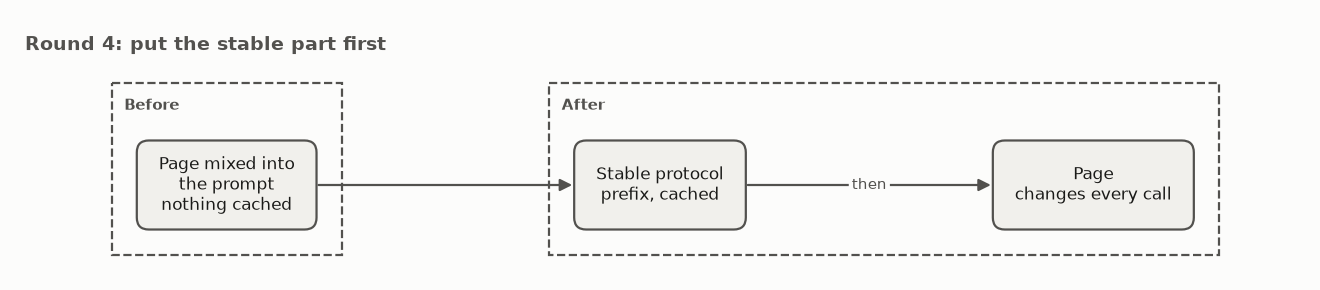

In [22]:
draw_diagram("round4")

metric,before,after
quality,0.98,0.98
privileged leaks,0,0
PII leaks,0,0
escalation rate,33%,33%
tool calls per page,0.1,0.1
sync tokens,"2,523","2,747"
p50 latency (s),0.68,0.65
model $/page,$0.00072,$0.00062
cost with attorney time $/page,$0.501,$0.501


Round 4: caching: ACCEPTED (guardrail pass 100%, floor 95%; failures: none)


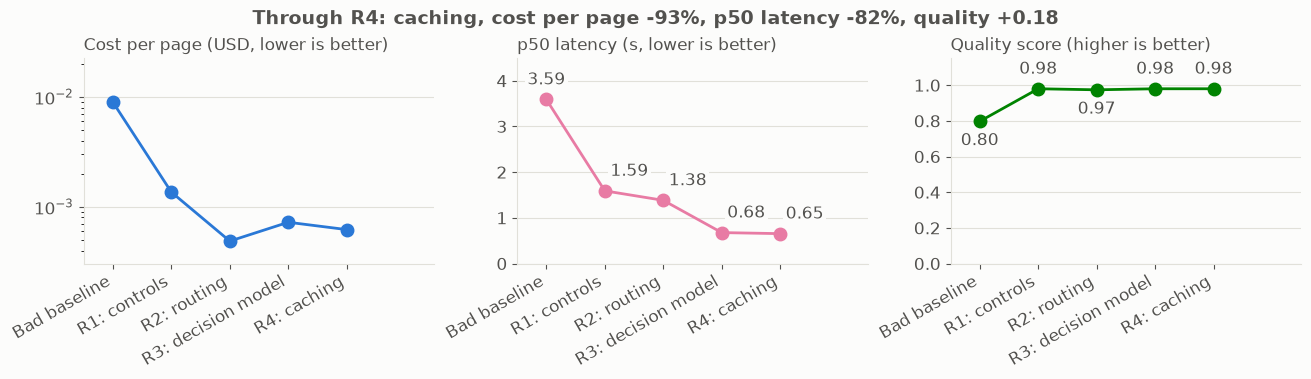

In [23]:
display(before_after(summary, DECISION_MODEL, CACHING).style.hide(axis="index"))
print(gate(traces, CACHING))
display(plot_progress(summary, upto_variant=CACHING))

## Step 11: Round 5, split the workflow

**What we changed:** the privilege log, QA and tags leave the page path and run later as Batch jobs (a queue the provider runs within 24 hours at 50% off).

**What happened:** p50 latency falls from 0.65s to 0.11s; model cost stays at about $0.00062 per page.

**Why:** side jobs nobody waits for should not slow the page.

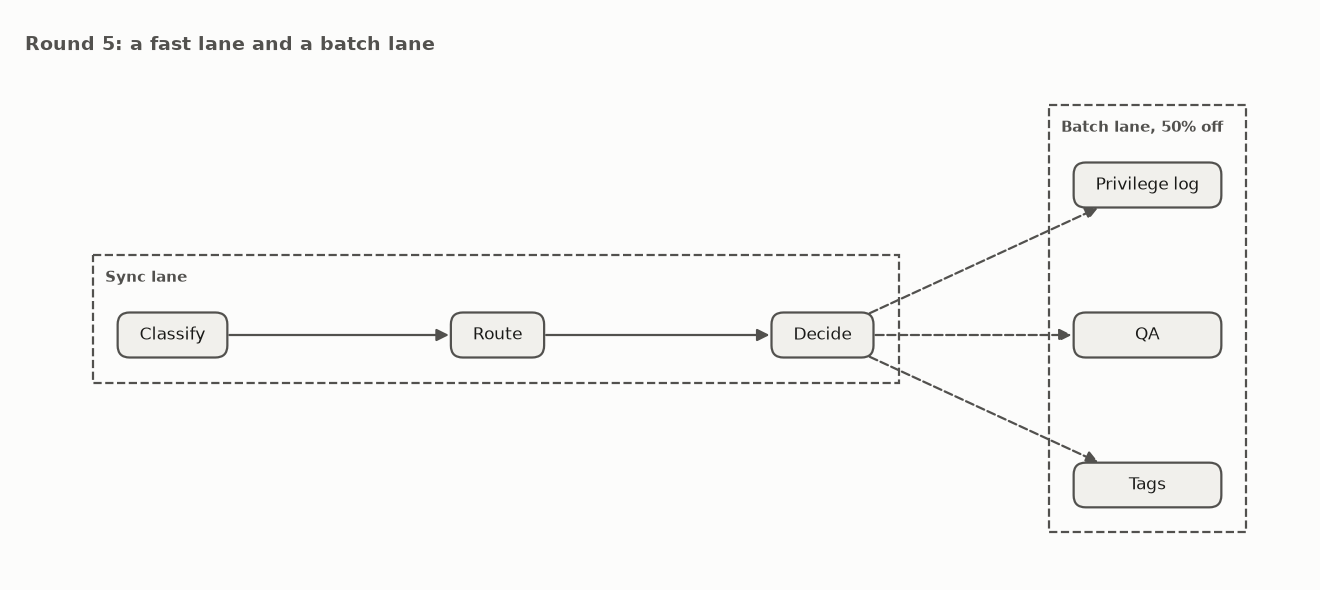

In [24]:
draw_diagram("round5")

metric,before,after
quality,0.98,0.98
privileged leaks,0,0
PII leaks,0,0
escalation rate,33%,33%
tool calls per page,0.1,0.1
sync tokens,"2,747","2,368"
p50 latency (s),0.65,0.11
model $/page,$0.00062,$0.00062
cost with attorney time $/page,$0.501,$0.501


Round 5: split workflow: ACCEPTED (guardrail pass 100%, floor 95%; failures: none)


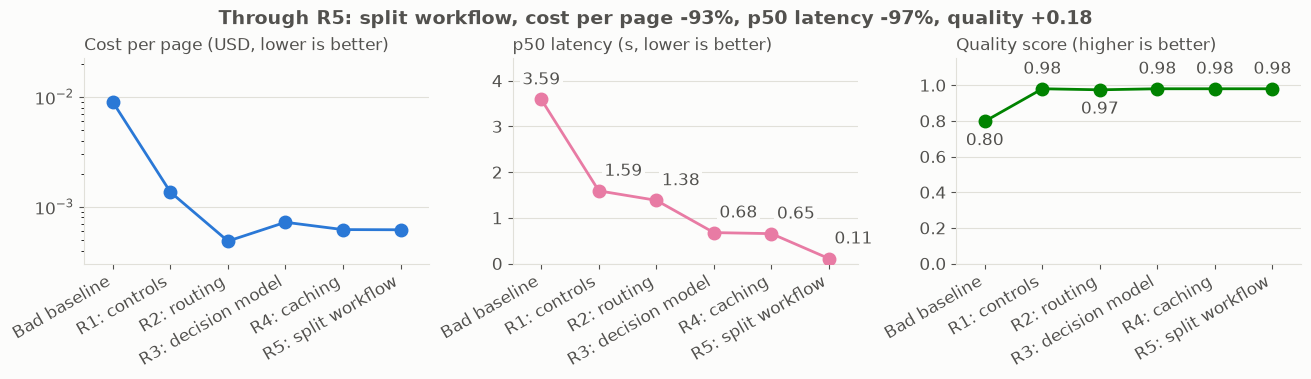

In [25]:
display(before_after(summary, CACHING, SPLIT).style.hide(axis="index"))
print(gate(traces, SPLIT))
display(plot_progress(summary, upto_variant=SPLIT))

## Step 12: Results

Every round on one chart, then every metric. Hard gates are on top and decide acceptance; the rest only warn.

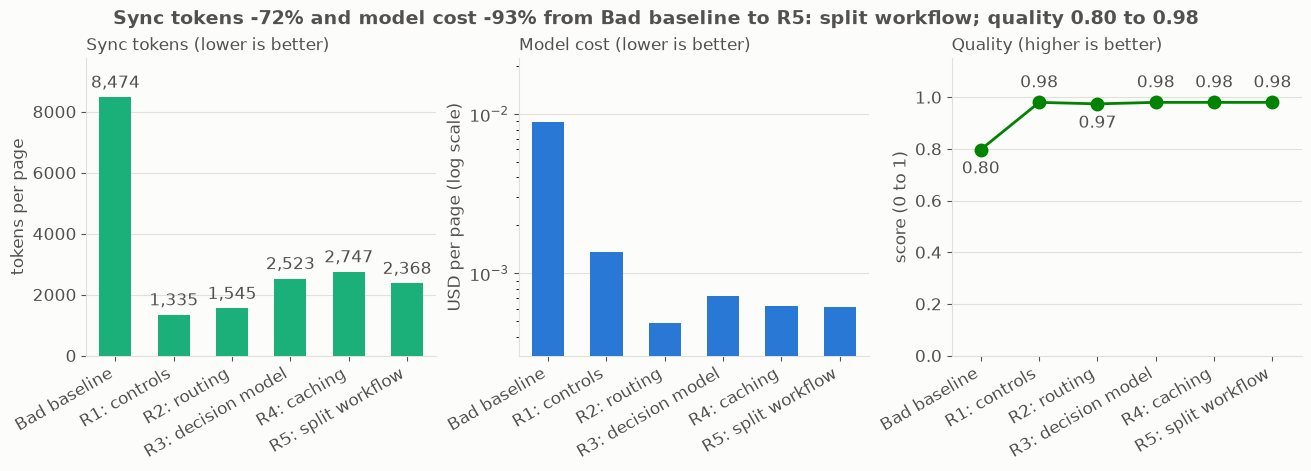

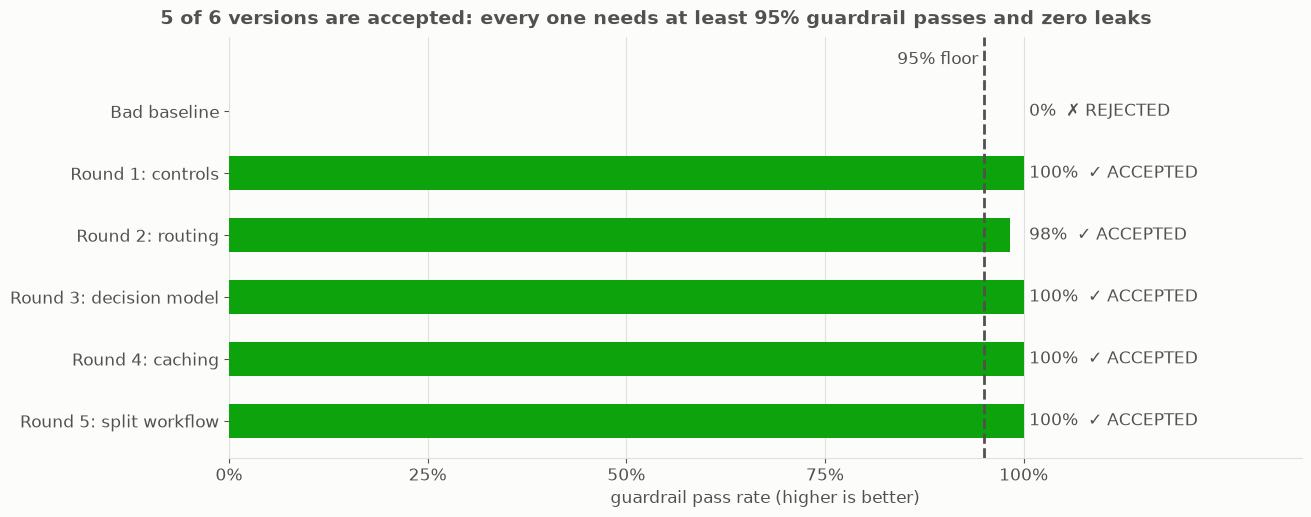

In [26]:
floor = get_settings().quality.guardrail_pass_floor
display(plot_round_chart(summary))
display(plot_quality_gate(gate_table(traces, VARIANT_ORDER), floor))

In [27]:
table = metrics_table(traces, VARIANT_ORDER)
display(table.rename(columns=lambda name: name.replace("Round ", "R").split(":")[0]).style.hide(axis="index"))
display(confusion_table(traces, SPLIT))

kind,metric,Bad baseline,R1,R2,R3,R4,R5
hard gate,privileged pages produced (must be 0),0,0,0,0,0,0
hard gate,PII leaked pages (must be 0),2,0,0,0,0,0
hard gate,guardrail pass rate (floor 95%),0%,100%,98%,100%,100%,100%
hard gate,round accepted,no,yes,yes,yes,yes,yes
reported,route accuracy,83% (watch),100%,98%,100%,100%,100%
reported,relevance recall,100%,100%,97%,100%,100%,100%
reported,over-withholding rate,0%,0%,3%,0%,0%,0%
reported,privileged recall,100%,100%,100%,100%,100%,100%
reported,PII recall,93% (watch),100%,100%,100%,100%,100%
reported,under-escalation rate,0%,0%,5%,0%,0%,0%


actual,produce,withhold,redact,attorney_review
expected,,,,
produce,18,0,0,0
withhold,0,12,0,0
redact,0,0,10,0
attorney_review,0,0,0,20


In [28]:
from doc_review_opt.experiment.metrics import classifications_by_page, holdout_check

report = holdout_check(classifications_by_page(engine_runs["decisions"]))
display(holdout_table(report).style.hide(axis="index"))
print(f"Leak-free on the unseen half: {report.holds} ({report.calibration_pages} and {report.holdout_pages} pages)")

policy,split,escalation rate,privileged leaks,PII leaks,quality,$/page
default,calibration,83%,0,0,0.78,$1.250
default,holdout,87%,0,0,0.76,$1.300
refit,calibration,50%,0,0,0.91,$0.750
refit,holdout,50%,0,0,0.91,$0.750


Leak-free on the unseen half: True (30 and 30 pages)


**Does calibration hold on unseen pages?** The policy is refit on one half of the pages (alternating within each route) and scored on the other. No leaks on unseen pages, and far cheaper than the default policy (default: 83% and 87% escalations). Escalations are 50% on the calibration half and 50% on the holdout half, and quality is 0.91 and 0.91. Only the holdout rows are out of sample; 30 pages is a small sample.

## Step 13: Live reality check

Real APIs, 2026-11-18, $0.18 total. The live run used 6 pages chosen from the original 30-page set, one per route in turn; the simulation above now uses all 60.

| Engine | Accuracy | $ / page | p50 |
|---|---|---|---|
| **Decisions** | 100% | $0.00019 | **0.38s** |
| `gpt-6-luna` LLM | 100% | **$0.00011** | 2.26s |
| `gpt-6.1-terra` LLM | 100% | $0.00073 | 3.03s |
| `gpt-6.1-terra` agent | 100% | $0.00118 | 2.33s |

Decisions is **about 6x faster** than `gpt-6-luna` and **4 to 6x cheaper** than `gpt-6.1-terra`, but **1.7x pricier** than `gpt-6-luna`.

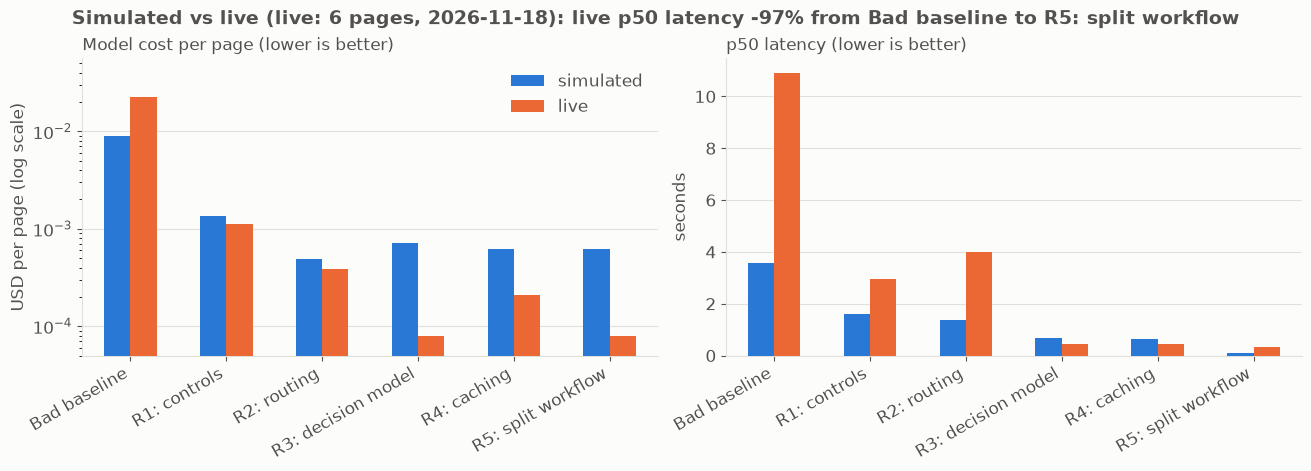

In [29]:
from doc_review_opt.reporting.reporting import plot_sim_vs_live, recorded_live_note, recorded_live_summary

display(plot_sim_vs_live(summary, recorded_live_summary(), recorded_live_note()))

**Reading the live chart.** Live Round 2 was slower than Round 1 (4.00s vs 2.96s) and scored lower (quality 0.95 vs 0.98). Live Decisions scored the same as Round 1 (0.98) on its 6 pages, while the 60-page simulation shows 83% route accuracy for Decisions alone. Live Round 4 caching cost more than Round 3 ($0.00021 vs $0.00008 per page).

Optional, on stage: rerun the engine comparison on the real APIs. It takes about a minute, costs a few cents and sends LangSmith traces.

In [30]:
from doc_review_opt.experiment.live import pick_live_pages
from doc_review_opt.experiment.tradeoffs import live_engine_comparison

if not RUN_LIVE_API_CALLS:
    print("Offline. Set RUN_LIVE_API_CALLS=true to rerun this on the real APIs.")
else:
    live_runs = await live_engine_comparison(pick_live_pages(EVAL_SET), client=client, budget=budget)
    if live_runs:
        show_engines(engine_comparison_table(live_runs))
        print("\n".join(f"{n}: {r.trace_url or 'LangSmith tracing is off'}" for n, r in live_runs.items()))
    print(f"Spend: ${budget.total_usd:.4f} of ${budget.limit_usd:.2f}")

Offline. Set RUN_LIVE_API_CALLS=true to rerun this on the real APIs.


## Step 14: Takeaways

1. **Measure first.** A labelled eval set and hard gates before any tuning.
2. **Cut waste before changing models.** Controls gave the biggest drop.
3. **Cheapest is not best.** Check what each round gives up.
4. **Typed decision? Try Decisions with a code router.** Fast, calibratable, auditable.
5. **Need text, tools or extraction? Keep an LLM**, the smallest that holds quality.
6. **Re-measure live.** In the live engine comparison, Decisions was the fastest engine (0.38s) and gpt-6-luna LLM the cheapest ($0.00011 per page); in the live rounds, routing was slower and caching cost more.

## References

Last verified: November 18, 2026.

- [Optimizing agents for cost and quality](https://github.com/openai/openai-cookbook/tree/main/examples/agent_optimization) (OpenAI Cookbook)
- [Document review agent](https://gist.github.com/sydney-runkle/a632ba4ea0b2b72501dfa4b6ab2a7d8a) (gist by Sydney Runkle)
- [Decisions API guide](https://developers.openai.com/api/docs/guides/decisions)
- [Pricing](https://developers.openai.com/api/docs/pricing)
- LangGraph [`Send`](https://langchain-ai.github.io/langgraph/concepts/low_level/#send) and [`interrupt`](https://langchain-ai.github.io/langgraph/concepts/human_in_the_loop/)